# 03 · Reversible training at the maximum batch size
Same reversible model as notebook 02, but the batch is pushed to the largest size that fits
in GPU memory (found by a doubling + bisection probe of a full fwd/bwd/AdamW step).
The token budget stays at 50M, so a bigger batch means **fewer optimizer steps**; peak LR is
scaled by √(B/32) (capped at 3e-3) and warmup is 5% of steps (min 10).

## 0. Setup
Runtime → Change runtime type → **GPU** (T4 is enough; L4/A100 are faster). Results and the tokenized data are cached on Google Drive (`USE_DRIVE=True`) so the notebooks can share them; set it to `False` to keep everything in `/content`.

In [1]:
import os, sys
USE_DRIVE = os.environ.get("REVLLM_USE_DRIVE", "1") == "1"   # persist data + results on Google Drive
SMOKE = os.environ.get("REVLLM_SMOKE", "0") == "1"   # True = tiny end-to-end pipeline check (~2 min)

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    WORK = "/content/drive/MyDrive/revllm-50m"
else:
    WORK = os.path.abspath("work")
os.makedirs(WORK, exist_ok=True)
DATA_DIR, RES_DIR = f"{WORK}/data", f"{WORK}/results"
print("work dir:", WORK)
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
!pip -q install tokenizers datasets

work dir: /content/repo/work
name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07


In [2]:
%%writefile revllm.py
"""
revllm.py - a ~20M-parameter GPT trained on 50M tokens, with memory-free
(reversible) backpropagation through the transformer stack.

Stack modes (ModelConfig.mode):
  standard  : ordinary pre-LN transformer, x <- x + F(x), autograd stores every activation.
  euler     : SAME forward as `standard` (forward Euler step x_{n+1} = x_n + F(x_n)),
              but activations are NOT stored. In backward, x_n is recovered from x_{n+1}
              by fixed-point iteration  x <- x_{n+1} - F(x)  (approximate inverse).
  midpoint  : leapfrog / explicit-midpoint two-step scheme
              x_{n+1} = x_{n-1} + F_n(x_n)   (i.e. x_{n+1} = x_{n-1} + 2h f(x_n))
              exactly invertible: x_{n-1} = x_{n+1} - F_n(x_n).
  revnet    : RevNet / Reformer additive coupling (a symplectic-Euler / leapfrog split):
              y1 = x1 + Attn(x2);  y2 = x2 + MLP(y1)
              exactly invertible: x2 = y2 - MLP(y1);  x1 = y1 - Attn(x2).

In all three reversible modes only the output state of the whole stack is kept for
backward; each block's activations are rebuilt on the fly, so activation memory
no longer grows with depth.

Everything (data, tokenizer, model, reversible autograd, trainer, batch-size probe)
lives in this one file so each notebook can run standalone on Colab.
"""
import os
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import json
import math
import time
from dataclasses import dataclass, asdict, field
from typing import Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint

EOS = "<|endoftext|>"
_LOG = os.environ.get("REVLLM_LOG")     # optional: mirror progress lines to a file


def print(*a, **k):                      # flush always; tee to $REVLLM_LOG if set
    import builtins
    builtins.print(*a, **k, flush=True)
    if _LOG:
        with open(_LOG, "a") as f:
            f.write(" ".join(str(x) for x in a) + "\n")


# ----------------------------------------------------------------------------------
# Data: TinyStories -> byte-level BPE (8k vocab) -> uint16 token files
# ----------------------------------------------------------------------------------
def _iter_texts(source, split):
    """Yield raw documents. `source` = 'tinystories' (HF hub) or a local .txt path
    (documents separated by blank lines / EOS) for offline testing."""
    if source == "tinystories":
        from datasets import load_dataset
        ds = load_dataset("roneneldan/TinyStories", split=split, streaming=True)
        for ex in ds:
            t = ex["text"].strip()
            if t:
                yield t
    else:
        with open(source, "r", encoding="utf-8") as f:
            raw = f.read()
        docs = [d.strip() for d in raw.replace(EOS, "\n\n").split("\n\n") if d.strip()]
        if split != "train":           # tiny local val split
            docs = docs[: max(1, len(docs) // 20)]
        for d in docs:
            yield d


def train_tokenizer(source, vocab_size, n_docs, path):
    from tokenizers import Tokenizer, models, pre_tokenizers, decoders, trainers
    tok = Tokenizer(models.BPE())
    tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=False)
    tok.decoder = decoders.ByteLevel()
    trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=[EOS],
                                  initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
                                  show_progress=False)

    def it():
        for i, t in enumerate(_iter_texts(source, "train")):
            if i >= n_docs:
                break
            yield t
    tok.train_from_iterator(it(), trainer=trainer)
    tok.save(path)
    return tok


def _encode_to_file(tok, source, split, n_tokens, path, batch_docs=4096):
    eos_id = tok.token_to_id(EOS)
    buf, out, count, t0 = [], [], 0, time.time()

    def flush():
        nonlocal count
        for enc in tok.encode_batch(buf):
            ids = enc.ids + [eos_id]
            out.append(np.asarray(ids, dtype=np.uint16))
            count += len(ids)
        buf.clear()

    for t in _iter_texts(source, split):
        buf.append(t)
        if len(buf) >= batch_docs:
            flush()
            if count >= n_tokens:
                break
    if buf and count < n_tokens:
        flush()
    arr = np.concatenate(out)[:n_tokens]
    arr.tofile(path)
    print(f"  {split}: {len(arr):,} tokens -> {path} ({time.time()-t0:.0f}s)")
    return len(arr)


def prepare_data(cache_dir="data", source="tinystories", vocab_size=8192,
                 n_train_tokens=51_000_000, n_val_tokens=1_000_000, tok_docs=100_000):
    """Idempotent. Returns dict(train=np.memmap, val=np.memmap, tokenizer=Tokenizer)."""
    from tokenizers import Tokenizer
    os.makedirs(cache_dir, exist_ok=True)
    tok_path = os.path.join(cache_dir, "tokenizer.json")
    tr_path, va_path = os.path.join(cache_dir, "train.bin"), os.path.join(cache_dir, "val.bin")
    if os.path.exists(tok_path):
        tok = Tokenizer.from_file(tok_path)
    else:
        t0 = time.time()
        tok = train_tokenizer(source, vocab_size, tok_docs, tok_path)
        print(f"  tokenizer trained ({tok.get_vocab_size()} tokens, {time.time()-t0:.0f}s)")
    need = lambda p, n: (not os.path.exists(p)) or os.path.getsize(p) // 2 < n
    if need(tr_path, n_train_tokens):
        _encode_to_file(tok, source, "train", n_train_tokens, tr_path)
    if need(va_path, min(n_val_tokens, 1)):
        _encode_to_file(tok, source, "validation", n_val_tokens, va_path)
    train = np.memmap(tr_path, dtype=np.uint16, mode="r")
    val = np.memmap(va_path, dtype=np.uint16, mode="r")
    print(f"data ready: train {len(train):,} tok | val {len(val):,} tok | vocab {tok.get_vocab_size()}")
    return dict(train=train, val=val, tokenizer=tok)


class Batcher:
    """Walks a random permutation of non-overlapping (T+1)-token windows: every training
    token is seen at most once, so `total_tokens` really is the number of tokens trained on."""
    def __init__(self, data, B, T, device, seed=0):
        self.data, self.B, self.T, self.device = data, B, T, device
        n = (len(data) - 1) // T
        self.starts = np.random.default_rng(seed).permutation(n) * T
        self.i = 0

    def next(self):
        if self.i + self.B > len(self.starts):
            self.i = 0
        s = self.starts[self.i:self.i + self.B]
        self.i += self.B
        idx = s[:, None] + np.arange(self.T + 1)[None, :]
        xy = torch.from_numpy(self.data[idx].astype(np.int64))
        if self.device.type == "cuda":
            xy = xy.pin_memory().to(self.device, non_blocking=True)
        return xy[:, :-1], xy[:, 1:]


# ----------------------------------------------------------------------------------
# Model
# ----------------------------------------------------------------------------------
@dataclass
class ModelConfig:
    vocab_size: int = 8192
    seq_len: int = 512
    d_model: int = 384
    n_layer: int = 10
    n_head: int = 6
    mlp_ratio: int = 4
    mode: str = "standard"      # standard | euler | midpoint | revnet
    euler_iters: int = 4        # fixed-point iterations for the approximate Euler inverse
    ce_chunk: int = 8192        # tokens per chunk in the (re-computed) LM-head + CE; 0 = off
    emb_std: float = 0.02       # init std of token/pos embeddings (sets residual-stream scale)


class Attn(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.ln = nn.LayerNorm(c.d_model)
        self.qkv = nn.Linear(c.d_model, 3 * c.d_model, bias=False)
        self.proj = nn.Linear(c.d_model, c.d_model, bias=False)
        self.h = c.n_head

    def forward(self, x):                      # returns the residual *update* only
        B, T, C = x.shape
        q, k, v = self.qkv(self.ln(x)).split(C, dim=2)
        q, k, v = (t.view(B, T, self.h, C // self.h).transpose(1, 2) for t in (q, k, v))
        y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.proj(y.transpose(1, 2).reshape(B, T, C))


class MLP(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.ln = nn.LayerNorm(c.d_model)
        self.fc = nn.Linear(c.d_model, c.mlp_ratio * c.d_model, bias=False)
        self.proj = nn.Linear(c.mlp_ratio * c.d_model, c.d_model, bias=False)

    def forward(self, x):
        return self.proj(F.gelu(self.fc(self.ln(x)), approximate="tanh"))


class Block(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.attn, self.mlp = Attn(c), MLP(c)

    def F(self, x):                            # full residual function: block(x) - x
        a = self.attn(x)
        return a + self.mlp(x + a)

    def forward(self, x):                      # standard pre-LN block
        x = x + self.attn(x)
        return x + self.mlp(x)


# ----------------------------------------------------------------------------------
# Reversible autograd: keep only the stack's output, rebuild activations in backward
# ----------------------------------------------------------------------------------
def _amp_state(x):
    dev = x.device.type
    return dev, torch.is_autocast_enabled(dev), torch.get_autocast_dtype(dev)


class RevTwoState(torch.autograd.Function):
    """Exactly-invertible two-state stacks: 'revnet' (coupling) and 'midpoint' (leapfrog)."""

    @staticmethod
    def forward(ctx, a, b, blocks, mode):
        for blk in blocks:                     # runs under no_grad -> nothing is stored
            if mode == "revnet":
                a = a + blk.attn(b)            # y1 = x1 + Attn(x2)
                b = b + blk.mlp(a)             # y2 = x2 + MLP(y1)
            else:                              # midpoint: (x_{n-1}, x_n) -> (x_n, x_{n-1} + F(x_n))
                a, b = b, a + blk.F(b)
        ctx.blocks, ctx.mode, ctx.amp = blocks, mode, _amp_state(a)
        ctx.save_for_backward(a, b)
        return a, b

    @staticmethod
    def backward(ctx, ga, gb):
        a, b = ctx.saved_tensors
        dev, amp_on, amp_dt = ctx.amp
        for blk in reversed(ctx.blocks):
            with torch.enable_grad(), torch.autocast(dev, dtype=amp_dt, enabled=amp_on):
                if ctx.mode == "revnet":       # a=y1, b=y2
                    y1 = a.detach().requires_grad_(True)
                    m = blk.mlp(y1)
                    x2 = (b - m.detach()).detach()                 # reconstruct x2
                    torch.autograd.backward(m, gb)                 # -> y1.grad, MLP params
                    g_y1 = ga + y1.grad
                    x2r = x2.requires_grad_(True)
                    at = blk.attn(x2r)
                    x1 = (a - at.detach()).detach()                # reconstruct x1
                    torch.autograd.backward(at, g_y1)              # -> x2.grad, Attn params
                    ga, gb = g_y1, gb + x2r.grad
                    a, b = x1, x2.detach()
                else:                          # midpoint: a=x_n, b=x_{n+1}
                    xn = a.detach().requires_grad_(True)
                    f = blk.F(xn)
                    x_prev = (b - f.detach()).detach()             # x_{n-1} = x_{n+1} - F(x_n)
                    torch.autograd.backward(f, gb)
                    ga, gb = gb, ga + xn.grad                      # grads wrt (x_{n-1}, x_n)
                    a, b = x_prev, xn.detach()
        return ga, gb, None, None


class RevEuler(torch.autograd.Function):
    """Forward Euler (the standard residual net) with an *approximate* inverse:
    x_n = x_{n+1} - F(x_n) solved by fixed-point iteration (converges if Lip(F) < 1)."""
    stats = {"recon_residual": float("nan")}
    track = True        # record the fixed-point residual (one host sync per layer)

    @staticmethod
    def forward(ctx, x, blocks, iters):
        for blk in blocks:
            x = x + blk.F(x)
        ctx.blocks, ctx.iters, ctx.amp = blocks, iters, _amp_state(x)
        ctx.save_for_backward(x)
        return x

    @staticmethod
    def backward(ctx, gy):
        (y,) = ctx.saved_tensors
        dev, amp_on, amp_dt = ctx.amp
        res = 0.0
        for blk in reversed(ctx.blocks):
            with torch.no_grad(), torch.autocast(dev, dtype=amp_dt, enabled=amp_on):
                x = y
                for k in range(ctx.iters):
                    x_new = y - blk.F(x)
                    if k == ctx.iters - 1 and RevEuler.track:   # last fixed-point step size
                        res = max(res, ((x_new - x).float().norm() / y.float().norm()).item())
                    x = x_new
            with torch.enable_grad(), torch.autocast(dev, dtype=amp_dt, enabled=amp_on):
                xr = x.detach().requires_grad_(True)
                out = xr + blk.F(xr)
                torch.autograd.backward(out, gy)
            gy, y = xr.grad, x.detach()
        RevEuler.stats["recon_residual"] = res
        return gy, None, None


# ----------------------------------------------------------------------------------
def _ce_sum(h, w, t):
    return F.cross_entropy(F.linear(h, w).float(), t, reduction="sum")


class GPT(nn.Module):
    def __init__(self, c: ModelConfig):
        super().__init__()
        self.c = c
        self.tok = nn.Embedding(c.vocab_size, c.d_model)
        self.pos = nn.Embedding(c.seq_len, c.d_model)
        self.blocks = nn.ModuleList([Block(c) for _ in range(c.n_layer)])
        self.ln_f = nn.LayerNorm(c.d_model)
        self.apply(self._init)
        nn.init.normal_(self.tok.weight, 0.0, c.emb_std)
        nn.init.normal_(self.pos.weight, 0.0, c.emb_std)
        for n, p in self.named_parameters():
            if n.endswith("proj.weight"):
                nn.init.normal_(p, 0.0, 0.02 / math.sqrt(2 * c.n_layer))

    @staticmethod
    def _init(m):
        if isinstance(m, (nn.Linear, nn.Embedding)):
            nn.init.normal_(m.weight, 0.0, 0.02)

    def n_params(self, non_embedding=False):
        n = sum(p.numel() for p in self.parameters())
        return n - (self.tok.weight.numel() + self.pos.weight.numel()) if non_embedding else n

    # -- the transformer stack, in every mode; reference=True uses plain autograd -------
    def stack(self, x, reference=False):
        c, blocks = self.c, self.blocks
        if c.mode == "standard":
            for blk in blocks:
                x = blk(x)
            return x
        if c.mode == "euler":
            if reference or not torch.is_grad_enabled():
                for blk in blocks:
                    x = x + blk.F(x)
                return x
            return RevEuler.apply(x, blocks, c.euler_iters)
        if reference or not torch.is_grad_enabled():
            a, b = x, x
            for blk in blocks:
                if c.mode == "revnet":
                    a = a + blk.attn(b)
                    b = b + blk.mlp(a)
                else:
                    a, b = b, a + blk.F(b)
        else:
            a, b = RevTwoState.apply(x, x, blocks, c.mode)
        return 0.5 * (a + b) if c.mode == "revnet" else b

    def forward(self, idx, targets=None, reference=False):
        B, T = idx.shape
        x = self.tok(idx) + self.pos(torch.arange(T, device=idx.device))
        h = self.ln_f(self.stack(x, reference))
        w = self.tok.weight                                          # tied LM head
        if targets is None:
            return F.linear(h[:, -1:], w).float()
        h2, t = h.reshape(-1, h.size(-1)), targets.reshape(-1)
        N, ch = t.numel(), self.c.ce_chunk
        if not torch.is_grad_enabled():                              # eval: chunk, no recompute
            k = ch if ch > 0 else 8192
            return sum(_ce_sum(h2[i:i+k], w, t[i:i+k]) for i in range(0, N, k)) / N
        if ch <= 0 or N <= ch:
            return _ce_sum(h2, w, t) / N
        # LM-head + CE in chunks, logits recomputed in backward (never all materialised)
        tot = 0.0
        for i in range(0, N, ch):
            tot = tot + checkpoint(_ce_sum, h2[i:i+ch], w, t[i:i+ch], use_reentrant=False)
        return tot / N

    @torch.no_grad()
    def generate(self, idx, n_new, temperature=0.8, top_k=40):
        for _ in range(n_new):
            logits = self(idx[:, -self.c.seq_len:])[:, -1] / temperature
            v, _ = torch.topk(logits, top_k)
            logits[logits < v[:, [-1]]] = -float("inf")
            idx = torch.cat([idx, torch.multinomial(F.softmax(logits, -1), 1)], 1)
        return idx


# ----------------------------------------------------------------------------------
# Diagnostics
# ----------------------------------------------------------------------------------
def grad_check(mode, device="cpu", euler_iters=4, seed=0, d=128, L=4, T=64, B=4, V=512,
               dtype=torch.float64, emb_std=0.02, branch_scale=4.0):
    """Compare reversible gradients against plain autograd on the same forward.
    Returns max relative error and cosine similarity over all parameter grads."""
    torch.manual_seed(seed)
    c = ModelConfig(vocab_size=V, seq_len=T, d_model=d, n_layer=L, n_head=4, mode=mode,
                    euler_iters=euler_iters, ce_chunk=0, emb_std=emb_std)
    m = GPT(c).to(device, dtype)
    # larger-than-init residual branches make the check meaningful (not ~identity)
    with torch.no_grad():
        for n, p in m.named_parameters():
            if n.endswith("proj.weight"):
                p.mul_(branch_scale)
    idx = torch.randint(0, V, (B, T), device=device)
    tgt = torch.randint(0, V, (B, T), device=device)
    ref_mode = "standard" if mode == "euler" else mode
    grads = {}
    for ref in (True, False):
        m.zero_grad(set_to_none=True)
        m.c.mode = ref_mode if ref else mode
        loss = m(idx, tgt, reference=ref)
        loss.backward()
        grads[ref] = torch.cat([p.grad.flatten() for p in m.parameters()])
    m.c.mode = mode
    g0, g1 = grads[True], grads[False]
    rel = ((g1 - g0).norm() / g0.norm()).item()
    cos = F.cosine_similarity(g0, g1, dim=0).item()
    return dict(mode=mode, euler_iters=euler_iters if mode == "euler" else None, emb_std=emb_std,
                rel_err=rel, cosine=cos, loss=loss.item(),
                euler_fixed_point_residual=RevEuler.stats["recon_residual"] if mode == "euler" else None)


def saved_activation_bytes(model, idx, tgt):
    """Bytes of tensors autograd saves for backward (activation memory), device-agnostic.
    Parameters are excluded."""
    params = {p.data_ptr() for p in model.parameters()}
    seen, total = set(), [0]

    def pack(t):
        if t.data_ptr() not in params and t.data_ptr() not in seen:
            seen.add(t.data_ptr())
            total[0] += t.numel() * t.element_size()
        return t
    with torch.autograd.graph.saved_tensors_hooks(pack, lambda t: t):
        loss = model(idx, tgt)
    loss.backward()
    model.zero_grad(set_to_none=True)
    return total[0]


# ----------------------------------------------------------------------------------
# Training
# ----------------------------------------------------------------------------------
@dataclass
class TrainConfig:
    run_name: str = "baseline"
    batch_size: int = 32
    total_tokens: int = 50_000_000
    lr: float = 1e-3
    min_lr_frac: float = 0.1
    warmup_frac: float = 0.05
    min_warmup: int = 10
    weight_decay: float = 0.1
    grad_clip: float = 1.0
    eval_every_tokens: int = 5_000_000
    eval_batches: int = 16
    final_eval_tokens: int = 500_000
    log_every: int = 10
    seed: int = 1337
    dtype: str = "auto"          # auto | bf16 | fp16 | fp32
    max_steps: Optional[int] = None   # smoke tests only
    out_dir: str = "results"
    sample_prompt: str = "Once upon a time"


def pick_dtype(name, device):
    if device.type != "cuda":
        return torch.float32 if name in ("auto", "fp32") else {"bf16": torch.bfloat16}.get(name, torch.float32)
    if name == "auto":
        return torch.bfloat16 if torch.cuda.is_bf16_supported() and \
            torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    return {"bf16": torch.bfloat16, "fp16": torch.float16, "fp32": torch.float32}[name]


def make_optimizer(model, lr, wd, device):
    decay = [p for n, p in model.named_parameters() if p.dim() >= 2]
    no_decay = [p for n, p in model.named_parameters() if p.dim() < 2]
    kw = dict(fused=True) if device.type == "cuda" else {}
    return torch.optim.AdamW([{"params": decay, "weight_decay": wd},
                              {"params": no_decay, "weight_decay": 0.0}],
                             lr=lr, betas=(0.9, 0.95), eps=1e-8, **kw)


def gpu_info():
    if not torch.cuda.is_available():
        return dict(device="cpu", torch=torch.__version__)
    p = torch.cuda.get_device_properties(0)
    return dict(device=p.name, total_mem_gb=round(p.total_memory / 2**30, 2),
                torch=torch.__version__, capability=list(torch.cuda.get_device_capability()))


@torch.no_grad()
def evaluate(model, data, B, T, device, amp_dtype, n_tokens=None, n_batches=None, seed=123):
    model.eval()
    n_batches = n_batches or max(1, math.ceil(n_tokens / (B * T)))
    bt = Batcher(data, B, T, device, seed=seed)
    tot = 0.0
    for _ in range(n_batches):
        x, y = bt.next()
        with torch.autocast(device.type, dtype=amp_dtype, enabled=amp_dtype != torch.float32):
            tot += model(x, y).item()
    model.train()
    return tot / n_batches


def train(mcfg: ModelConfig, tcfg: TrainConfig, data, device=None, verbose=True):
    device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(tcfg.seed)
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True
    amp_dtype = pick_dtype(tcfg.dtype, device)
    use_amp = amp_dtype != torch.float32
    is_cuda = device.type == "cuda"
    if is_cuda:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    model = GPT(mcfg).to(device)
    opt = make_optimizer(model, tcfg.lr, tcfg.weight_decay, device)
    scaler = torch.amp.GradScaler("cuda", enabled=(amp_dtype == torch.float16 and is_cuda))
    B, T = tcfg.batch_size, mcfg.seq_len
    tok_per_step = B * T
    steps = math.ceil(tcfg.total_tokens / tok_per_step)
    if tcfg.max_steps:
        steps = min(steps, tcfg.max_steps)
    warmup = max(tcfg.min_warmup, int(tcfg.warmup_frac * steps))
    warmup = min(warmup, max(1, steps // 2))

    def lr_at(s):
        if s < warmup:
            return tcfg.lr * (s + 1) / warmup
        p = (s - warmup) / max(1, steps - warmup)
        return tcfg.lr * (tcfg.min_lr_frac + (1 - tcfg.min_lr_frac) * 0.5 * (1 + math.cos(math.pi * p)))

    bt = Batcher(data["train"], B, T, device, seed=tcfg.seed)
    eval_B = min(B, 64)
    eval_every = max(1, round(tcfg.eval_every_tokens / tok_per_step))
    hist = dict(step=[], tokens=[], loss=[], lr=[], tok_s=[], val_step=[], val_tokens=[], val_loss=[])
    if verbose:
        print(f"[{tcfg.run_name}] mode={mcfg.mode} params={model.n_params()/1e6:.2f}M "
              f"B={B} T={T} tok/step={tok_per_step:,} steps={steps} warmup={warmup} "
              f"lr={tcfg.lr:.2e} amp={amp_dtype}")

    static_mem, train_time, t_log, tok_log = None, 0.0, None, 0
    loss_window, nonfinite = [], 0
    steady_tok, steady_time = 0, 0.0
    t_start = time.time()
    for s in range(steps):
        if is_cuda:
            torch.cuda.synchronize()
        t0 = time.time()
        for g in opt.param_groups:
            g["lr"] = lr_at(s)
        x, y = bt.next()
        with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
            loss = model(x, y)
        scaler.scale(loss).backward()
        scaler.unscale_(opt)
        gn = torch.nn.utils.clip_grad_norm_(model.parameters(), tcfg.grad_clip)
        scaler.step(opt)
        scaler.update()
        opt.zero_grad(set_to_none=True)
        if is_cuda:
            torch.cuda.synchronize()
        dt = time.time() - t0
        train_time += dt
        if s >= 5:                                 # skip warm-up / allocator settling steps
            steady_tok += tok_per_step
            steady_time += dt
        if static_mem is None and is_cuda:
            static_mem = torch.cuda.memory_allocated()   # params + grads(None) + Adam states
        lv = loss.item()
        if not math.isfinite(lv):
            nonfinite += 1
        loss_window.append(lv)
        if s % tcfg.log_every == 0 or s == steps - 1:
            ts = tok_per_step / dt
            hist["step"].append(s); hist["tokens"].append((s + 1) * tok_per_step)
            hist["loss"].append(lv); hist["lr"].append(lr_at(s)); hist["tok_s"].append(ts)
            if verbose:
                mem = torch.cuda.max_memory_allocated() / 2**30 if is_cuda else 0
                extra = f" recon={RevEuler.stats['recon_residual']:.1e}" if mcfg.mode == "euler" else ""
                print(f"  step {s:5d}/{steps} loss {lv:.4f} gnorm {gn:.2f} lr {lr_at(s):.2e} "
                      f"{ts/1e3:7.1f}k tok/s peak {mem:.2f}GB{extra}")
        if nonfinite > 20:
            print("  !! loss diverged (non-finite), stopping")
            break
        if (s + 1) % eval_every == 0 and s != steps - 1:
            vl = evaluate(model, data["val"], eval_B, T, device, amp_dtype, n_batches=tcfg.eval_batches)
            hist["val_step"].append(s); hist["val_tokens"].append((s + 1) * tok_per_step)
            hist["val_loss"].append(vl)
            if verbose:
                print(f"  -- val loss {vl:.4f} @ {(s+1)*tok_per_step/1e6:.1f}M tokens")

    wall = time.time() - t_start
    final_val = evaluate(model, data["val"], eval_B, T, device, amp_dtype, n_tokens=tcfg.final_eval_tokens)
    hist["val_step"].append(steps - 1); hist["val_tokens"].append(steps * tok_per_step)
    hist["val_loss"].append(final_val)
    peak_alloc = torch.cuda.max_memory_allocated() / 2**30 if is_cuda else None
    peak_res = torch.cuda.max_memory_reserved() / 2**30 if is_cuda else None
    sample = ""
    if "tokenizer" in data and data["tokenizer"] is not None:
        tok = data["tokenizer"]
        ids = torch.tensor([tok.encode(tcfg.sample_prompt).ids], device=device)
        with torch.autocast(device.type, dtype=amp_dtype, enabled=use_amp):
            out = model.generate(ids, 120)
        sample = tok.decode(out[0].tolist())
    tail = [l for l in loss_window[-50:] if math.isfinite(l)]
    res = dict(
        run_name=tcfg.run_name, model=asdict(mcfg), train=asdict(tcfg), hw=gpu_info(),
        amp_dtype=str(amp_dtype), n_params=model.n_params(),
        n_params_non_embedding=model.n_params(non_embedding=True),
        steps=len(loss_window), tokens_trained=len(loss_window) * tok_per_step,
        tokens_per_step=tok_per_step, warmup_steps=warmup,
        final_train_loss=float(np.mean(tail)) if tail else float("nan"),
        final_val_loss=final_val, diverged=nonfinite > 20,
        tokens_per_sec=steady_tok / steady_time if steady_time else tok_per_step * len(loss_window) / train_time,
        train_time_s=train_time, wall_time_s=wall,
        peak_mem_alloc_gb=peak_alloc, peak_mem_reserved_gb=peak_res,
        static_mem_gb=static_mem / 2**30 if static_mem else None,
        activation_mem_gb=(peak_alloc - static_mem / 2**30) if (peak_alloc and static_mem) else None,
        euler_recon_residual=RevEuler.stats["recon_residual"] if mcfg.mode == "euler" else None,
        sample=sample, history=hist,
    )
    if verbose:
        print(f"[{tcfg.run_name}] DONE  train_loss {res['final_train_loss']:.4f}  val_loss {final_val:.4f}  "
              f"{res['tokens_per_sec']/1e3:.1f}k tok/s  peak {peak_alloc or 0:.2f}GB  "
              f"time {train_time/60:.1f} min")
    os.makedirs(tcfg.out_dir, exist_ok=True)
    with open(os.path.join(tcfg.out_dir, f"{tcfg.run_name}.json"), "w") as f:
        json.dump(res, f, indent=1)
    del model, opt
    if is_cuda:
        torch.cuda.empty_cache()
    return res


# ----------------------------------------------------------------------------------
# Max-batch probe
# ----------------------------------------------------------------------------------
def _try_batch(model, opt, scaler, B, T, V, device, amp_dtype):
    loss = x = None
    try:
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        x = torch.randint(0, V, (B, T), device=device)
        with torch.autocast("cuda", dtype=amp_dtype, enabled=amp_dtype != torch.float32):
            loss = model(x, x)
        scaler.scale(loss).backward()
        scaler.step(opt)
        scaler.update()
        opt.zero_grad(set_to_none=True)
        torch.cuda.synchronize()
        return True, torch.cuda.max_memory_allocated() / 2**30
    except torch.cuda.OutOfMemoryError:
        opt.zero_grad(set_to_none=True)
        return False, None
    finally:
        loss = x = None
        torch.cuda.empty_cache()


def probe_max_batch(mcfg: ModelConfig, dtype="auto", start=8, limit=4096, granularity=8, verbose=True):
    """Largest batch (sequences of length seq_len) whose fwd+bwd+AdamW step fits on the GPU.
    Doubling search, then bisection to `granularity`."""
    device = torch.device("cuda")
    amp_dtype = pick_dtype(dtype, device)
    model = GPT(mcfg).to(device)
    opt = make_optimizer(model, 1e-4, 0.1, device)
    scaler = torch.amp.GradScaler("cuda", enabled=amp_dtype == torch.float16)
    T, V = mcfg.seq_len, mcfg.vocab_size
    trace, ok_B, bad_B, B = [], 0, None, start
    while B <= limit:
        ok, mem = _try_batch(model, opt, scaler, B, T, V, device, amp_dtype)
        trace.append(dict(batch=B, ok=ok, peak_gb=mem))
        if verbose:
            print(f"  B={B:5d}  {'ok ' if ok else 'OOM'}  {'' if mem is None else f'{mem:.2f} GB'}")
        if not ok:
            bad_B = B
            break
        ok_B, B = B, B * 2
    if bad_B is not None:
        lo, hi = ok_B, bad_B
        while hi - lo > granularity:
            mid = (lo + hi) // 2 // granularity * granularity
            if mid <= lo:
                break
            ok, mem = _try_batch(model, opt, scaler, mid, T, V, device, amp_dtype)
            trace.append(dict(batch=mid, ok=ok, peak_gb=mem))
            if verbose:
                print(f"  B={mid:5d}  {'ok ' if ok else 'OOM'}  {'' if mem is None else f'{mem:.2f} GB'}")
            lo, hi = (mid, hi) if ok else (lo, mid)
        ok_B = lo
    del model, opt
    torch.cuda.empty_cache()
    oks = sorted([t for t in trace if t["ok"]], key=lambda t: t["batch"])
    slope = None
    if len(oks) >= 2:                             # GB per extra sequence (activation memory)
        slope = (oks[-1]["peak_gb"] - oks[0]["peak_gb"]) / (oks[-1]["batch"] - oks[0]["batch"])
    res = dict(mode=mcfg.mode, max_batch=ok_B, max_tokens_per_step=ok_B * T,
               hit_limit=bad_B is None, gb_per_sequence=slope, trace=trace, hw=gpu_info())
    if verbose:
        print(f"  => max batch for mode={mcfg.mode}: {ok_B} sequences ({ok_B*T:,} tokens/step)"
              + (f", {slope*1024:.1f} MB/sequence" if slope else ""))
    return res


def save_json(obj, path):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    with open(path, "w") as f:
        json.dump(obj, f, indent=1)


Overwriting revllm.py


In [3]:
import importlib, json, math, torch
import revllm as R; importlib.reload(R)
import matplotlib.pyplot as plt
print(torch.__version__, R.gpu_info())

TOTAL_TOKENS = 50_000_000 if not SMOKE else 400_000
DATA_SOURCE = os.environ.get("REVLLM_SOURCE", "tinystories")   # or a local .txt for offline tests
data = R.prepare_data(DATA_DIR, source=DATA_SOURCE, vocab_size=8192,
                      n_train_tokens=51_000_000 if not SMOKE else 1_000_000,
                      n_val_tokens=1_000_000 if not SMOKE else 100_000)
BASE_KW = dict(vocab_size=data["tokenizer"].get_vocab_size())
if SMOKE:                          # tiny model so the smoke test also runs on CPU
    BASE_KW.update(d_model=128, n_layer=4, n_head=4, seq_len=128)
M = lambda **kw: R.ModelConfig(**{**BASE_KW, **kw})   # d=384, 10 layers, 6 heads, T=512, vocab 8192
print(M())
print("params:", f"{R.GPT(M()).n_params()/1e6:.2f}M",
      "| non-embedding:", f"{R.GPT(M()).n_params(non_embedding=True)/1e6:.2f}M")
HAS_GPU = torch.cuda.is_available()

2.11.0+cu128 {'device': 'Tesla T4', 'total_mem_gb': 14.56, 'torch': '2.11.0+cu128', 'capability': [7, 5]}


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


README.md:   0%|          | 0.00/1.06k [00:00<?, ?B/s]

  tokenizer trained (8192 tokens, 58s)


  train: 51,000,000 tokens -> /content/repo/work/data/train.bin (125s)


  validation: 1,000,000 tokens -> /content/repo/work/data/val.bin (5s)


data ready: train 51,000,000 tok | val 1,000,000 tok | vocab 8192


ModelConfig(vocab_size=8192, seq_len=512, d_model=384, n_layer=10, n_head=6, mlp_ratio=4, mode='standard', euler_iters=4, ce_chunk=8192, emb_std=0.02)


params: 21.05M | non-embedding: 17.71M


In [4]:
def plot_runs(runs, title=""):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for r in runs:
        h = r["history"]
        ax[0].plot([t/1e6 for t in h["tokens"]], h["loss"], label=r["run_name"], alpha=.8)
        ax[1].plot([t/1e6 for t in h["val_tokens"]], h["val_loss"], "o-", label=r["run_name"])
    for a, t in zip(ax, ["train loss", "val loss"]):
        a.set_xlabel("tokens (M)"); a.set_ylabel(t); a.grid(alpha=.3); a.legend()
    ax[0].set_ylim(top=min(6, ax[0].get_ylim()[1]))
    fig.suptitle(title); plt.tight_layout(); plt.show()

def show(r):
    keys = ["run_name", "steps", "tokens_trained", "final_train_loss", "final_val_loss",
            "tokens_per_sec", "peak_mem_alloc_gb", "peak_mem_reserved_gb", "activation_mem_gb", "train_time_s"]
    for k in keys:
        v = r.get(k)
        print(f"  {k:22s} {v:,.4f}" if isinstance(v, float) else f"  {k:22s} {v}")
    print("  sample:", r["sample"][:400])

In [5]:
p = f"{RES_DIR}/chosen_variant.json"
BEST = R.ModelConfig(**json.load(open(p))["model"]) if os.path.exists(p) else M(mode="revnet")
print("variant:", BEST.mode)
probe_rev = R.probe_max_batch(BEST, limit=4096 if not SMOKE else 64) if HAS_GPU else     dict(mode=BEST.mode, max_batch=64, max_tokens_per_step=64 * BEST.seq_len, hit_limit=True,
         gb_per_sequence=None, trace=[], hw=R.gpu_info())      # CPU smoke-test stand-in
R.save_json(probe_rev, f"{RES_DIR}/probe_{BEST.mode}.json")
if os.path.exists(f"{RES_DIR}/probe_standard.json"):
    ps = json.load(open(f"{RES_DIR}/probe_standard.json"))
    print(f"max batch  standard: {ps['max_batch']}   reversible ({BEST.mode}): {probe_rev['max_batch']}"
          f"   -> {probe_rev['max_batch']/ps['max_batch']:.1f}x")

variant: midpoint


  B=    8  ok   0.48 GB


  B=   16  ok   1.04 GB


  B=   32  ok   1.11 GB


  B=   64  ok   1.27 GB


...

  B=  960  OOM  


  B=  928  ok   13.94 GB


  B=  944  ok   14.18 GB


  B=  952  OOM  


  => max batch for mode=midpoint: 944 sequences (483,328 tokens/step), 15.0 MB/sequence


[03_reversible_bmax] mode=midpoint params=21.05M B=944 T=512 tok/step=483,328 steps=104 warmup=10 lr=3.00e-03 amp=torch.float16


  step     0/104 loss 9.0806 gnorm 11.97 lr 3.00e-04    55.2k tok/s peak 14.02GB


  step     5/104 loss 6.7634 gnorm 1.74 lr 1.80e-03    55.5k tok/s peak 14.18GB


  -- val loss 5.9667 @ 4.8M tokens


  step    10/104 loss 5.9575 gnorm 2.20 lr 3.00e-03    54.7k tok/s peak 14.18GB


...

  -- val loss 5.6179 @ 48.3M tokens


  step   100/104 loss 5.5730 gnorm 0.06 lr 3.12e-04    52.9k tok/s peak 14.18GB


  step   103/104 loss 5.5757 gnorm 0.07 lr 3.01e-04    53.1k tok/s peak 14.18GB


[03_reversible_bmax] DONE  train_loss 5.5812  val_loss 5.6162  53.4k tok/s  peak 14.18GB  time 15.7 min


  run_name               03_reversible_bmax
  steps                  104
  tokens_trained         50266112
  final_train_loss       5.5812
  final_val_loss         5.6162
  tokens_per_sec         53,365.5461
  peak_mem_alloc_gb      14.1775
  peak_mem_reserved_gb   14.3887
  activation_mem_gb      13.9227
  train_time_s           940.0243
  sample: Once upon a time, and.
 They.The't day on, a said.
 The and the the.

 It and it he. I.
 His and.

 The he and. She the. He saw.
 She. The. They to.



 He,. From a little to on, the,, happy. 
 She.
 He was was not.
 They a little and with, so. 
 From, and a. They a they.
 They his.


 He.
 They big on big. The you the it on


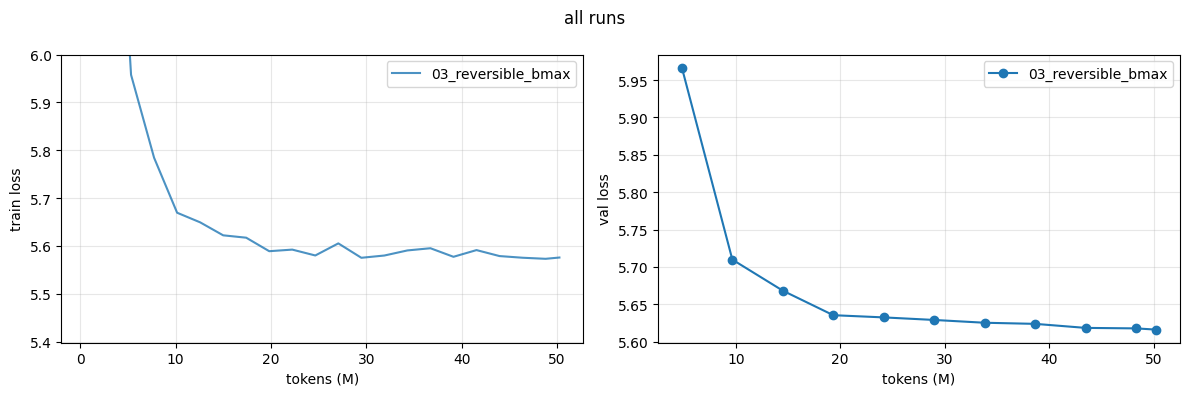

In [6]:
B_MAX = probe_rev["max_batch"]
lr = min(3e-3, 1e-3 * math.sqrt(B_MAX / 32))
while True:                                   # back off in steps of 8 if the real run OOMs
    try:
        big = R.train(BEST, R.TrainConfig(run_name="03_reversible_bmax", batch_size=B_MAX,
                      total_tokens=TOTAL_TOKENS, lr=lr, eval_every_tokens=5_000_000,
                      out_dir=RES_DIR, log_every=5), data)
        break
    except torch.cuda.OutOfMemoryError:
        torch.cuda.empty_cache(); B_MAX -= 8; print("OOM -> retry with B =", B_MAX)
show(big)
runs = [json.load(open(f"{RES_DIR}/{n}.json")) for n in ["01_baseline_b32", "02_reversible_b32"]
        if os.path.exists(f"{RES_DIR}/{n}.json")] + [big]
plot_runs(runs, "all runs")